# Reproducing across laboratories

A screen at scale comes from more than one laboratory. This page uses JUMP-Target-2, the plate the JUMP
consortium {cite:p}`Chandrasekaran_2023` ran at every participating laboratory, so any difference between two
copies of it is technical.

JUMP calls a participating laboratory a source, and this page uses that column throughout: `Metadata_Source`,
with values from `source_2` to `source_13`. In a CellProfiler export, `Metadata_Site` is a field of view inside
a well, which this page does not use.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

import mantispy as mt

warnings.formatwarning = lambda message, category, *a, **k: f"{category.__name__}: {message}\n"

## JUMP-Target-2

`mt.ds.jump_target2()` downloads one TARGET2 plate from each of the eleven sources that ran it,
and joins the JUMP annotation onto them. The plate map is identical at every source, and source_9
runs it four times over on a 1536-well plate; only the laboratory differs.

In [2]:
jump = mt.ds.jump_target2()
{
    "shape": jump.shape,
    "sources": jump.obs["Metadata_Source"].value_counts().to_dict(),
    "perturbations": int(jump.obs["Metadata_Perturbation"].nunique()),
    "control wells": int(jump.obs["Metadata_Control"].sum()),
}

{'shape': (5374, 3616),
 'sources': {'source_9': 1536,
  'source_10': 384,
  'source_13': 384,
  'source_3': 384,
  'source_4': 384,
  'source_5': 384,
  'source_6': 384,
  'source_7': 384,
  'source_8': 384,
  'source_11': 383,
  'source_2': 383},
 'perturbations': 302,
 'control wells': 898}

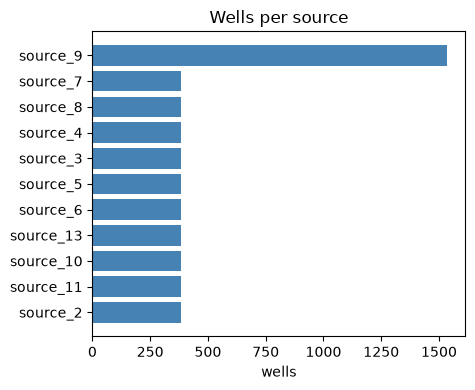

In [3]:
counts = jump.obs["Metadata_Source"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(5, 4))
ax.barh(counts.index.astype(str), counts.to_numpy(), color="steelblue")
ax.set_xlabel("wells")
ax.set_title("Wells per source")
fig.tight_layout()
plt.show()

Wells contributed by each source. source_9 has 1536 (a 1536-well plate); the others have about 384 each.

The perturbation annotation comes from the JUMP metadata repository, joined by `mt.io.read_jump`; see
[Published profiles and JUMP](../tutorials/data/profiles.ipynb).

## The same pipeline

The recipe does not change for data from eleven laboratories.

In [4]:
mt.pp.normalize(jump, method="mad_robustize", by="Metadata_Plate", reference="negcon")
mt.pp.feature_select(jump, na_cutoff=0.0)
jump = mt.pp.subset_features(jump)

{
    "features kept": jump.n_vars,
    "control wells per source": jump.obs.groupby("Metadata_Source", observed=True)["Metadata_Control"].sum().to_dict(),
}

{'features kept': 603,
 'control wells per source': {'source_10': 64,
  'source_11': 64,
  'source_13': 64,
  'source_2': 65,
  'source_3': 64,
  'source_4': 64,
  'source_5': 64,
  'source_6': 65,
  'source_7': 64,
  'source_8': 64,
  'source_9': 256}}

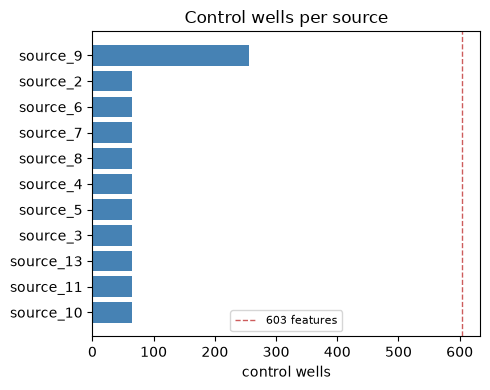

In [5]:
controls = jump.obs.groupby("Metadata_Source", observed=True)["Metadata_Control"].sum().sort_values()
fig, ax = plt.subplots(figsize=(5, 4))
ax.barh(controls.index.astype(str), controls.to_numpy(), color="steelblue")
ax.axvline(jump.n_vars, color="indianred", ls="--", lw=1, label=f"{jump.n_vars} features")
ax.set_xlabel("control wells")
ax.set_title("Control wells per source")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Control wells per source (bars) against the number of features kept (dashed line). Every source has fewer control wells than features.

## The batch metrics

`mt.metrics.evaluate_integration` runs the integration benchmark over each representation and draws it as a
heatmap, one row per representation, with higher better in every cell. It returns the numeric results frame too.

The benchmark comes from [scib-metrics](https://scib-metrics.readthedocs.io), imported through
`pip install "mantispy[integration,map]"` rather than reimplemented; mantispy reads its public results and
renders the heatmap. The columns group into blocks: bio conservation (cLISI is how label-pure a well's
neighbourhood is), batch correction (iLISI is how batch-mixed it is, PCR comparison how much less of the variance
the batch explains after correction), and the aggregate scores. With
[copairs](https://github.com/cytomining/copairs) also installed the heatmap gains a retrieval block, the
cross-replicate mean average precision (mAP), and a second aggregate column beside scib-metrics' `Total`:
mantispy's `Total+mAP`, which folds mAP into the bio group. Without scib-metrics it draws the mAP column alone,
and with neither it raises and points to `mt.metrics.batch_variance_explained` (stack several covariates) or
`mt.metrics.pc_regression` (a single covariate) for a native batch-variance check.

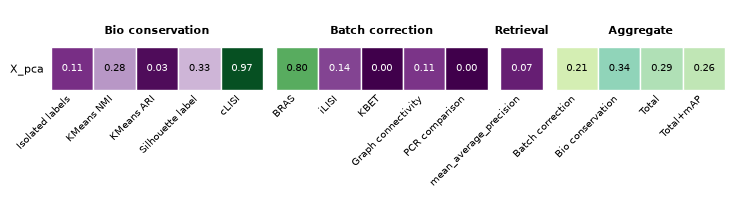

In [6]:
sc.pp.pca(jump, n_comps=30)
mt.metrics.evaluate_integration(jump, label_key="Metadata_Perturbation", batch_key="Metadata_Source");

In [7]:
mt.pl.batch_variance(jump, keys=["Metadata_Source", "Metadata_Perturbation"]);

## Cross-source retrieval

Batch metrics ask whether the sites mix. A screen needs to know whether the same compound, run
at different sites, produces the same profile. That is a retrieval task, with `pos_sameby` set to the
perturbation and `pos_diffby` to the source.

The next cell computes the baseline, three corrections and an ICC feature filter.

In [8]:
def cross_source_map(adata, use_rep=None):
    """Mean average precision for retrieving a compound across sites."""
    treated = adata[~adata.obs["Metadata_Control"].to_numpy()].copy()
    mt.tl.map(
        treated,
        pos_sameby=["Metadata_Perturbation"],
        pos_diffby=["Metadata_Source"],
        neg_diffby=["Metadata_Perturbation"],
        use_rep=use_rep,
        null_size=500,
        seed=0,
    )
    table = treated.uns["mantispy"]["map"]
    return round(float(table["score"].mean()), 3), int(table["is_significant"].sum())


n_treated = int(jump.obs.loc[~jump.obs["Metadata_Control"].to_numpy(), "Metadata_Perturbation"].nunique())
variants = {"per-plate normalize only": jump}

per_source = jump.copy()
mt.pp.sphere(per_source, method="ZCA-cor", reference="negcon", by="Metadata_Source")
variants["+ sphere per source"] = per_source

pooled = jump.copy()
mt.pp.sphere(pooled, method="ZCA-cor", reference="negcon")
variants["+ sphere pooled controls"] = pooled

regressed = jump.copy()
mt.pp.regress_out(regressed, keys=["Metadata_Source"], by=None, reference=None)
variants["+ regress out source"] = regressed

reproducible = jump.copy()
mt.pp.feature_reproducibility(reproducible, by="Metadata_Perturbation", min_icc=0.2)
reproducible = reproducible[:, reproducible.var["icc_selected"].to_numpy()].copy()
variants["+ keep ICC > 0.2"] = reproducible

map_variants = pd.DataFrame(
    [
        {"pipeline": name, "features": adata.n_vars, "cross-source mAP": score, f"significant of {n_treated}": count}
        for name, adata in variants.items()
        for score, count in [cross_source_map(adata)]
    ]
)
map_variants

,pipeline,features,cross-source mAP,significant of 301
0,per-plate normalize only,603,0.021,79
1,+ sphere per source,603,0.021,117
2,+ sphere pooled controls,603,0.008,0
3,+ regress out source,603,0.004,0
4,+ keep ICC > 0.2,253,0.028,122


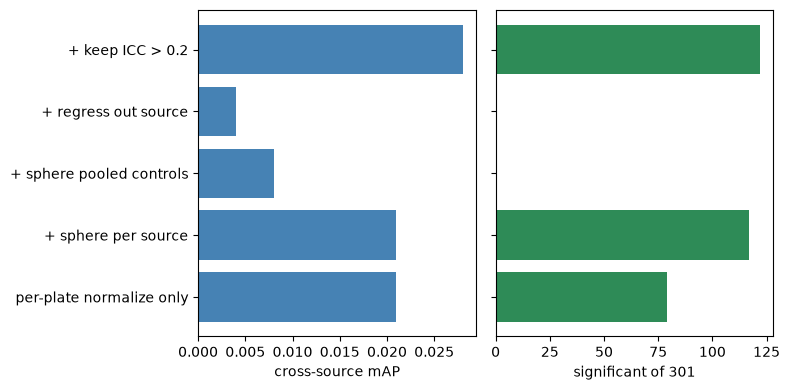

In [9]:
order = map_variants.set_index("pipeline")
sig_col = [c for c in order.columns if c.startswith("significant")][0]
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)
axes[0].barh(order.index, order["cross-source mAP"], color="steelblue")
axes[0].set_xlabel("cross-source mAP")
axes[1].barh(order.index, order[sig_col], color="seagreen")
axes[1].set_xlabel(sig_col)
fig.tight_layout()
plt.show()

Left: cross-source mAP per pipeline. Right: compounds significant of 301. Sphering pooled controls and regressing out source give the lowest values; keeping ICC > 0.2 gives the highest.

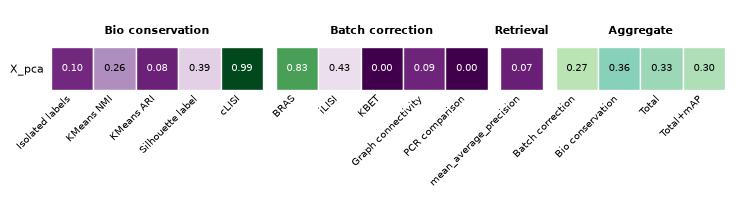

In [10]:
# The batch metrics again, after sphering per source.
sphered = variants["+ sphere per source"].copy()
sc.pp.pca(sphered, n_comps=30)
mt.metrics.evaluate_integration(
    sphered, reps=("X_pca",), label_key="Metadata_Perturbation", batch_key="Metadata_Source"
);

Compare that heatmap with the metrics above. Sphering per source lifts the batch-correction side of the heatmap,
and here retrieval agrees: the mAP holds, and 117 compounds are recovered above chance instead of 79. Sphering on
the pooled controls and regressing out the source recover none. Keeping the features whose replicates agree, which
is not a batch correction, recovers the most.

Judge a correction by the retrieval the screen needs. The mixing metrics describe the batches, not whether the
biology survived.

With one plate per site, there are 64 or 65 control wells per site (256 at source_9) against 603 features, so
a per-source covariance is underdetermined, yet sphering per source still helped here. With twenty plates per site the result could differ.

## Is it the regularization, or the pooling?

Sphering divides out the control covariance; the `ZCA-cor` variant used here does it on the correlation matrix, standardizing each feature against the controls first. That division is unstable in directions where the controls barely vary, so a regularization term, `epsilon`, is added to steady it: a larger `epsilon` means gentler whitening, and a large enough one reduces the whitening to almost nothing. mantispy's default is a small fixed `epsilon`; `epsilon="auto"` instead reproduces the consortium's own sphering search. It uses the same log-uniform grid and the same objective, the mean of a candidate's activity and replicate-retrieval mAP, and keeps the best. It then samples past both ends of that grid, and between points, when the best sits there, so the search can follow the signal out of the recipe's range if that is where it leads.

In [11]:
auto = jump.copy()
mt.pp.sphere(auto, method="ZCA-cor", reference="negcon", epsilon="auto")
sweep = auto.uns["mantispy"]["sphere_epsilon"]


def sweep_objective(adata):
    """The activity and replicate-retrieval mAP that epsilon="auto" maximizes."""
    activity = mt.tl.map(adata, mode="activity", null_size=0, seed=0, copy=True)
    replicability = mt.tl.map(adata, mode="replicability", null_size=0, seed=0, copy=True)
    return (activity.uns["mantispy"]["map"]["score"].mean() + replicability.uns["mantispy"]["map"]["score"].mean()) / 2


default = jump.copy()
mt.pp.sphere(default, method="ZCA-cor", reference="negcon", epsilon=1e-6)
default_score = sweep_objective(default)

controls = jump[jump.obs["Metadata_Control"].to_numpy()]
eigenvalues = np.linalg.eigvalsh(np.corrcoef(np.asarray(controls.X, dtype=float), rowvar=False))
{
    "fixed default epsilon": 1e-6,
    "fixed default score": round(float(default_score), 3),
    "recipe search range": (1e-5, 1e3),
    "chosen epsilon": round(float(sweep["epsilon"])),
    "chosen score": round(float(np.max(sweep["scores"])), 3),
    "largest control-correlation eigenvalue": round(float(eigenvalues.max()), 1),
}

{'fixed default epsilon': 1e-06,
 'fixed default score': 0.152,
 'recipe search range': (1e-05, 1000.0),
 'chosen epsilon': 861345,
 'chosen score': 0.161,
 'largest control-correlation eigenvalue': 79.5}

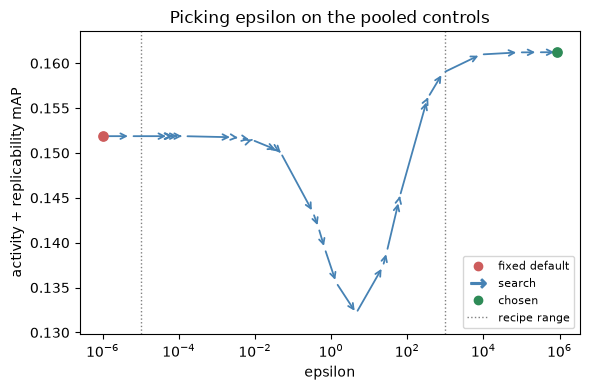

In [12]:
grid = np.asarray(sweep["grid"], dtype=float)
scores = np.asarray(sweep["scores"], dtype=float)
ok = np.isfinite(scores)
order = np.argsort(grid[ok])
# the chain: the fixed default, then every candidate the search scored, by increasing epsilon
xs = np.concatenate(([1e-6], grid[ok][order]))
ys = np.concatenate(([default_score], scores[ok][order]))

fig, ax = plt.subplots(figsize=(6, 4))
ax.axvline(1e-5, color="grey", ls=":", lw=1)
ax.axvline(1e3, color="grey", ls=":", lw=1)
for i in range(len(xs) - 1):
    ax.annotate(
        "",
        xy=(xs[i + 1], ys[i + 1]),
        xytext=(xs[i], ys[i]),
        arrowprops={"arrowstyle": "->", "color": "steelblue", "lw": 1.3},
    )
best = int(np.argmax(ys))
ax.scatter([xs[0]], [ys[0]], color="indianred", s=45, zorder=3)
ax.scatter([xs[best]], [ys[best]], color="seagreen", s=45, zorder=3)
ax.plot([], [], color="indianred", marker="o", ls="", label="fixed default")
ax.plot([], [], color="steelblue", marker=r"$\rightarrow$", ls="", markersize=11, label="search")
ax.plot([], [], color="seagreen", marker="o", ls="", label="chosen")
ax.plot([], [], color="grey", ls=":", lw=1, label="recipe range")
ax.set_xscale("log")
ax.set_xlim(xs.min() / 4, xs.max() * 4)
pad = 0.08 * (ys.max() - ys.min())
ax.set_ylim(ys.min() - pad, ys.max() + pad)
ax.set_xlabel("epsilon")
ax.set_ylabel("activity + replicability mAP")
ax.set_title("Picking epsilon on the pooled controls")
ax.legend(loc="best", fontsize=8)
fig.tight_layout()
plt.show()

In [13]:
pd.DataFrame(
    [
        {"pipeline": name, "cross-source mAP": m, f"significant of {n_treated}": s}
        for name, (m, s) in {
            "per-plate normalize only": cross_source_map(jump),
            "+ sphere pooled, fixed epsilon": cross_source_map(pooled),
            "+ sphere pooled, auto epsilon": cross_source_map(auto),
        }.items()
    ]
)

,pipeline,cross-source mAP,significant of 301
0,per-plate normalize only,0.021,79
1,"+ sphere pooled, fixed epsilon",0.008,0
2,"+ sphere pooled, auto epsilon",0.024,110


The fixed default sits below the recipe range, and the search leaves it by the other end: the score is still rising past the top of the grid and flattens only far beyond it, at an `epsilon` larger than any eigenvalue of the control correlation (above), where the whitening it keeps is close to none. Both regimes agree: heavy whitening at small `epsilon` and almost none at large `epsilon` score about the same, while the partial whitening in between is worst. The whole curve spans a narrow band, a small gain over the default.

So the search does not find a regularization that makes pooled sphering work; it backs the whitening off until the transform nearly vanishes, which is the data declining the correction. The head-to-head agrees: `auto` recovers essentially the normalize-only mAP, far from the fixed default's collapse, and the extra compounds it calls significant (110 against 79) come from `ZCA-cor`'s per-feature re-standardization, not from the covariance reshaping, which at this `epsilon` is off. On significant compounds it stays below sphering per source (117).

Read a search that leaves its range and flattens, as here, as a diagnostic: pooled covariance correction is the wrong tool for this screen, because the pooled control correlation is set by the differences between the laboratories. Sphering helps most within a source, where the controls share one correlation structure, and it is not in JUMP's compound recipe at all, which is the next section.

## What the consortium's recipe does

JUMP has three recipes, and the perturbation type decides which one applies.
`jump-profiling-recipe` names them in its configs. For compounds, which TARGET-2 contains,
`compound.json` specifies

```
profiles_var_mad_int_featselect_harmony
```

that is, variance-based feature selection, MAD normalization against the negative controls, the rank
inverse normal transform, feature selection and Harmony. The ORF and CRISPR branches use a
different pipeline, `profiles_wellpos_cc_var_mad_outlier_featselect_sphering_harmony`, which
adds well position correction, cell count regression, outlier removal and sphering.

Sphering is in the ORF and CRISPR branches, and the `epsilon` search above is exactly how the recipe sets it there, but not in the compound pipeline. The diagnostic above is why: run on this compound screen, that same search tunes the whitening away to almost nothing. mantispy leaves the choice to the data rather than to a fixed rule: `mt.pp.sphere` is available, and `epsilon="auto"` is the recipe's own search, which here declines the step. The two steps of the compound pipeline that the comparison above does not include are covered below, and both behave differently from the corrections in that table.

`pp.rank_int` is the rank inverse normal transform. Each feature's values are replaced by
their normal scores within a plate, so only the ordering of the wells is kept and the scale is
discarded. Every feature ends up standard normal by construction, which is a strong assumption
about your data, so check what it costs.

In [14]:
inted = jump.copy()
mt.pp.rank_int(inted, by="Metadata_Plate")

# The reference implementation ranks each feature over the whole screen; ranking within a
# plate additionally removes any plate-level difference in the shape of the distribution.
globally = jump.copy()
mt.pp.rank_int(globally)

inted_icc = inted.copy()
mt.pp.feature_reproducibility(inted_icc, by="Metadata_Perturbation", min_icc=0.2)
inted_icc = inted_icc[:, inted_icc.var["icc_selected"].to_numpy()].copy()

rankint_variants = pd.DataFrame(
    [
        {"pipeline": name, "features": adata.n_vars, "cross-source mAP": score, f"significant of {n_treated}": count}
        for name, adata in [
            ("per-plate normalize only", jump),
            ("+ rank INT, ranked globally", globally),
            ("+ rank INT, ranked per plate", inted),
            ("+ rank INT per plate, then ICC > 0.2", inted_icc),
        ]
        for score, count in [cross_source_map(adata)]
    ]
)
rankint_variants

,pipeline,features,cross-source mAP,significant of 301
0,per-plate normalize only,603,0.021,79
1,"+ rank INT, ranked globally",603,0.023,113
2,"+ rank INT, ranked per plate",603,0.033,126
3,"+ rank INT per plate, then ICC > 0.2",61,0.034,150


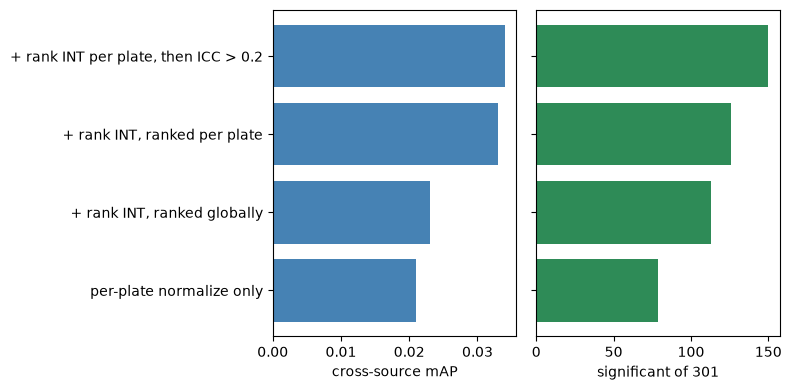

In [15]:
order = rankint_variants.set_index("pipeline")
sig_col = [c for c in order.columns if c.startswith("significant")][0]
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)
axes[0].barh(order.index, order["cross-source mAP"], color="steelblue")
axes[0].set_xlabel("cross-source mAP")
axes[1].barh(order.index, order[sig_col], color="seagreen")
axes[1].set_xlabel(sig_col)
fig.tight_layout()
plt.show()

Left: cross-source mAP per ranking choice. Right: compounds significant of 301. Ranking per plate is higher than ranking globally or normalize-only, and adding the ICC filter is higher still.

Ranking per plate helps more than any correction above, and the ICC filter adds to it on only 61
features.
Ranking globally helps less (113 significant, against 126 per plate).

Where you rank matters. The reference implementation ranks each feature over the whole
screen, which is the `by=None` default. Ranking within each plate works better here,
because it also removes plate-to-plate differences in the shape of a
feature's distribution, which with one plate per site are the differences between sites.

The transform discards magnitude, and distance from the controls depends on magnitude, so
check the effect on activity as well:

In [16]:
def activity(adata):
    """Phenotypic activity: can each compound be told from the negative controls?"""
    scratch = adata.copy()
    mt.tl.map(scratch, mode="activity", null_size=500, seed=0)
    table = scratch.uns["mantispy"]["map"]
    return round(float(table["score"].mean()), 3), int(table["is_significant"].sum())


activity_compare = {"per-plate normalize only": activity(jump), "+ rank INT": activity(inted)}
activity_compare

{'per-plate normalize only': (0.249, 110), '+ rank INT': (0.289, 117)}

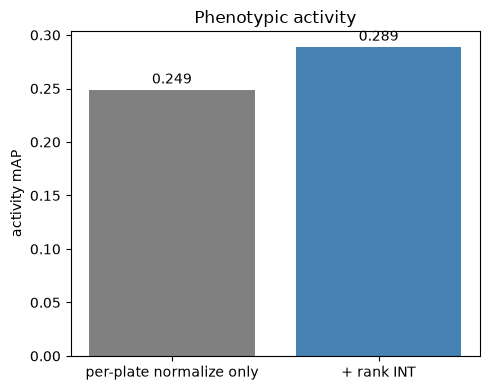

In [17]:
labels = list(activity_compare)
maps = [activity_compare[k][0] for k in labels]
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(labels, maps, color=["grey", "steelblue"])
ax.bar_label(bars, padding=2)
ax.set_ylabel("activity mAP")
ax.set_title("Phenotypic activity")
fig.tight_layout()
plt.show()

Phenotypic activity mAP before and after the rank INT transform. It is slightly higher after the transform.

Here it costs nothing, and activity rises too. That need not generalize: this is one plate per
source and 603 features. The
outcome depends on the screen, so measure both before adopting it.

## Harmony, and a metric that disagrees with retrieval

`pp.harmony` ranked in the top three in every scenario of the batch-correction benchmark
{cite:p}`Arevalo_2024`, as did Seurat RPCA, and is the last step of the recipe.
It works on an embedding rather than on features (it alternates soft clustering and
per-cluster linear correction), so it returns a corrected `obsm`, not a corrected `X`. It needs the optional extra,
`pip install 'mantispy[harmony]'`. Its result moves with the seed and the row order;
[Learned embeddings against CellProfiler](learned_embeddings.ipynb) measures how much the seed moves it.

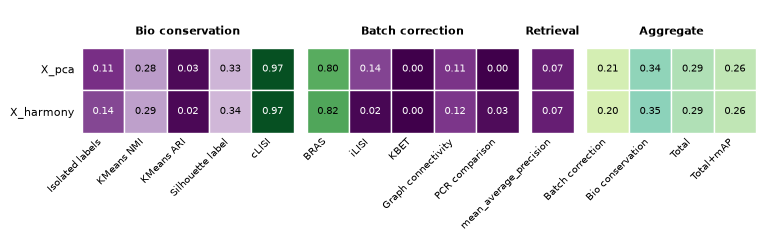

In [18]:
harmonised = jump.copy()  # carries the X_pca from above
mt.pp.harmony(harmonised, batch_key="Metadata_Source", use_rep="X_pca")

mt.metrics.evaluate_integration(
    harmonised, reps=("X_pca", "X_harmony"), label_key="Metadata_Perturbation", batch_key="Metadata_Source"
);

In [19]:
def centroid_spread(embedding):
    """Mean distance of the site centroids from their mean."""
    centroids = pd.DataFrame(embedding).groupby(harmonised.obs["Metadata_Source"].to_numpy()).mean()
    return round(float(np.linalg.norm(centroids - centroids.mean(), axis=1).mean()), 1)


harmony_compare = {
    key: {
        "site centroid spread": centroid_spread(harmonised.obsm[key]),
        "cross-source mAP": cross_source_map(harmonised, use_rep=key),
    }
    for key in ("X_pca", "X_harmony")
}
harmony_compare

{'X_pca': {'site centroid spread': 418.1, 'cross-source mAP': (0.017, 61)},
 'X_harmony': {'site centroid spread': 343.5, 'cross-source mAP': (0.02, 67)}}

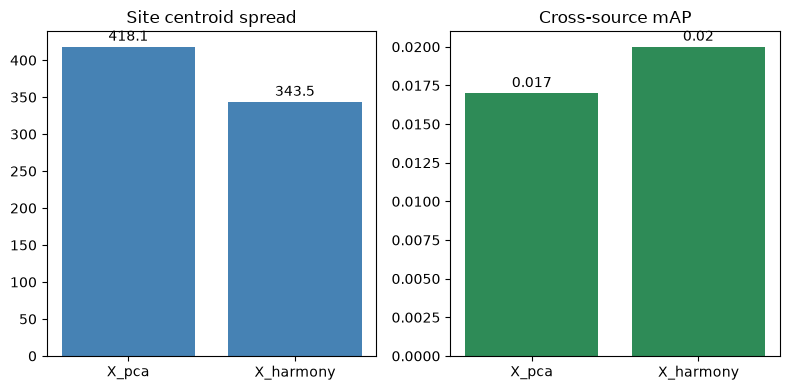

In [20]:
keys = list(harmony_compare)
spread = [harmony_compare[k]["site centroid spread"] for k in keys]
maps = [harmony_compare[k]["cross-source mAP"][0] for k in keys]
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
b0 = axes[0].bar(keys, spread, color="steelblue")
axes[0].bar_label(b0, padding=2)
axes[0].set_title("Site centroid spread")
b1 = axes[1].bar(keys, maps, color="seagreen")
axes[1].bar_label(b1, padding=2)
axes[1].set_title("Cross-source mAP")
fig.tight_layout()
plt.show()

Left: mean spread of the site centroids for PCA and Harmony. Right: cross-source mAP for the same two. Harmony lowers the centroid spread and raises the mAP slightly.

Harmony pulls the site centroids about 18% closer and raises cross-source retrieval slightly, yet the batch-mixing
side of the heatmap above disagrees: iLISI falls sharply.

iLISI asks whether a well's nearest neighbors come from several sites. Harmony aligns the sites
globally without mixing local neighborhoods, so a well stays surrounded by wells from its own
site while the site clouds move together. Both observations hold, and retrieval is the one that
answers the screen's question.

harmonypy can report convergence and return the embedding unchanged. `pp.harmony` compares its
output with its input and warns when they are identical, so that uncorrected numbers do not
pass unnoticed through the rest of the pipeline.

## Which compounds reproduce across sites?

The results above are aggregates: one mAP for the screen, one LISI per representation. Follow-up
work needs to know which compounds reproduced, which the page has not yet shown.

`tl.transport` answers that. It computes each perturbation's effect as its profile minus the
control centroid of its own setting, so a baseline offset does not count as disagreement, and
measures how well those effect vectors agree across settings. `by=` takes a list from coarsest
to finest level, and each pair of plates is assigned to the coarsest level at which the two
differ, so every comparison belongs to exactly one level.

With one plate per laboratory, as so far, laboratory and plate effects are the same comparison
and cannot be separated. The next cell loads twelve of the 141 plates `jump_target2` pins: three
sources, two batches each, two plates per batch.

This section uses only the per-plate `mad_robustize` normalization from earlier, without
`rank_int`, Harmony or the other corrections evaluated above. Its numbers are an uncorrected
baseline on a different set of plates and are not comparable with the eleven-plate mAP values
earlier on this page.

In [21]:
hierarchy = mt.ds.jump_target2(
    plates=["JCPQC051", "JCPQC052", "JCPQC053", "JCPQC054"]
    + ["BR00121438", "BR00121439", "BR00126113", "BR00126114"]
    + ["110000294936", "110000296682", "110000296339", "110000296356"]
)
mt.pp.normalize(hierarchy, method="mad_robustize", by="Metadata_Plate", reference="negcon")
hierarchy = hierarchy[:, ~hierarchy.var["degenerate_scale"].to_numpy()].copy()
mt.pp.feature_select(hierarchy, na_cutoff=0.0)
hierarchy = mt.pp.subset_features(hierarchy)

mt.tl.transport(hierarchy, by=["Metadata_Source", "Metadata_Batch", "Metadata_Plate"])
by_level = hierarchy.uns["mantispy"]["transport"]
by_level.groupby("level", observed=True).agg(
    compounds=("group", "size"),
    agreement=("agreement", "median"),
    reproduce=("is_significant", "sum"),
).round(3).reindex(["Metadata_Plate", "Metadata_Batch", "Metadata_Source"])

  0%|                                              | 0.00/13.3M [00:00<?, ?B/s]

  1%|▏                                     | 69.6k/13.3M [00:00<00:35, 375kB/s]

  2%|▋                                      | 218k/13.3M [00:00<00:15, 857kB/s]

  4%|█▍                                    | 504k/13.3M [00:00<00:07, 1.61MB/s]

 10%|███▌                                 | 1.28M/13.3M [00:00<00:03, 3.78MB/s]

...

 88%|████████████████████████████████▍    | 38.2M/43.7M [00:02<00:00, 28.6MB/s]

 95%|███████████████████████████████████▏ | 41.6M/43.7M [00:02<00:00, 30.0MB/s]

  0%|                                              | 0.00/43.7M [00:00<?, ?B/s]

100%|█████████████████████████████████████| 43.7M/43.7M [00:00<00:00, 40.2GB/s]

,compounds,agreement,reproduce
level,,,
Metadata_Plate,301,0.475,75
Metadata_Batch,301,0.365,75
Metadata_Source,301,0.134,61


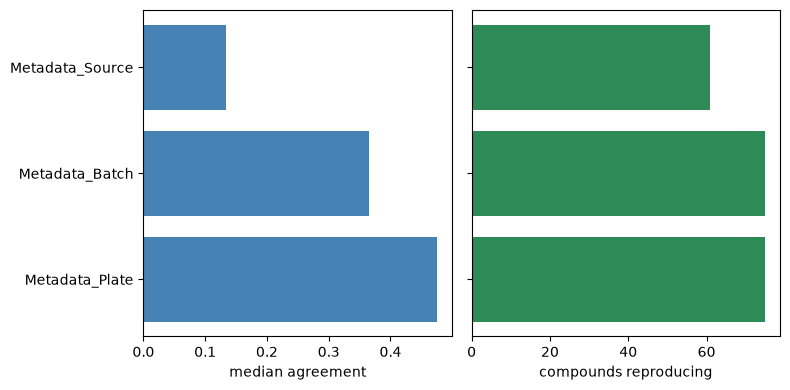

In [22]:
levels = ["Metadata_Plate", "Metadata_Batch", "Metadata_Source"]
summary = (
    by_level.groupby("level", observed=True)
    .agg(
        agreement=("agreement", "median"),
        reproduce=("is_significant", "sum"),
    )
    .reindex(levels)
)
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)
axes[0].barh(levels, summary["agreement"], color="steelblue")
axes[0].set_xlabel("median agreement")
axes[1].barh(levels, summary["reproduce"], color="seagreen")
axes[1].set_xlabel("compounds reproducing")
fig.tight_layout()
plt.show()

Left: median effect agreement at each level. Right: compounds reproducing at q < 0.05. Agreement falls from plate to batch to source.

Read the table row by row. A compound's effect agrees at +0.475 between two plates of one
batch, at +0.365 between batches of one laboratory, and at +0.134 between laboratories. Each
step up the hierarchy lowers agreement, and the step between laboratories costs about twice
as much as the step between batches.

A single aggregate cross-source mAP shows that the sites disagree, but not whether to fix
plate handling or the protocol. The gap between levels does.

The `reproduce` column counts the compounds whose agreement beats the null at q < 0.05. The
null uses every mismatched pair of compounds at that level instead of a sample. A sampled null
would not give Benjamini-Hochberg enough resolution: its smallest possible p-value is one over
the number of draws, so the count would reflect the number of draws rather than the screen.

`pl.setting_agreement`, in the figure below, reads the same effect vectors by plate instead of
by compound: it shows which of the twelve plates agree with each other. Annotating by source
draws a line at each laboratory boundary, so a laboratory that disagrees with itself appears as
a broken block. Its cells are an activity-weighted mean over compounds, while the table's
per-level number is an unweighted median, so the heatmap reads higher than the table for the
same pair of settings. Use it to see which settings differ from each other, not to compare
absolute levels with the table.

In [23]:
mt.pl.setting_agreement(hierarchy, by="Metadata_Source");

## Summary

- "Site" is ambiguous in this field. JUMP's source is a laboratory; CellProfiler's
  `Metadata_Site` is a field of view.
- Judge a correction by the question your screen asks. On this data iLISI
  and retrieval disagreed about Harmony, and the corrections that pooled the sites left no
  compound significant.
- Reproducibility has levels. `tl.transport` separates them, and the gap between two levels
  is more actionable than either value alone. It is an observational measure: it supports
  "this effect did not reproduce at the other site", but not "this effect would have been
  *x* at the other site".

Next: [Learned embeddings against CellProfiler](learned_embeddings.ipynb), the same question asked of six
feature sets.